# 2 · Solving a graph problem with atoms: maximum independent set

The blockade from notebook 1 is exactly the constraint of a famous graph problem. An **independent set** of a graph is a set of nodes with no edge between any two of them. Finding the **largest** one, the *maximum independent set* (MIS), is NP-hard and appears in scheduling, wireless network design and portfolio selection.

The idea: put one atom per node, close together when the nodes share an edge. The blockade then forbids exciting both ends of an edge, and a slow pulse pushes the atoms to excite as many as possible.

In this notebook you will:

1. define a small graph and solve it by brute force,
2. encode it in atom positions,
3. write an *annealing* pulse as a piecewise-linear schedule and run it,
4. read the answer from the measurements,
5. use the GPU to tune the pulse before spending QPU time on it,
6. take the challenge: beat the tuned pulse with your own.

**CUDA-Q you will use:** a piecewise-linear `RydbergHamiltonian` from waveform samples, and `evolve_async` to run a grid of programs.

In [1]:
# Copyright 2026 Pasqal
# SPDX-License-Identifier: Apache-2.0
import itertools
import math
import warnings

warnings.filterwarnings("ignore", message="The CUDA-Q `sample` and `observe`", category=FutureWarning)

import cudaq
from cudaq.dynamics import Schedule
from cudaq.operators import RydbergHamiltonian, ScalarOperator
import matplotlib.pyplot as plt
import numpy as np

from cudaq_pasqal import draw
from cudaq_pasqal.analyze import probability, rydberg_density

C6 = 865723.02e-30  # level 60, as in notebook 1, in rad m⁶ s⁻¹
cudaq.set_target("pasqal", emulate=True, emulation_rydberg_c6=str(C6))
cudaq.set_random_seed(7)
plt.rcParams.update({"figure.figsize": (7, 3.5), "font.size": 11})

## 1. The graph and its answer

Our graph has four nodes and four edges. We write a candidate solution as a bitstring $z$, with $z_i = 1$ if node $i$ is selected. The MIS minimises the cost

$$
E(z) = -\sum_i z_i + 2\sum_{(i,j)\in\text{edges}} z_i z_j ,
$$

where each selected node earns $-1$ and each violated edge costs $+2$. With four nodes there are only $2^4 = 16$ candidates, so we can check them all:

Optimal sets: ['0101', '0110'] → nodes [[1, 3], [1, 2]]


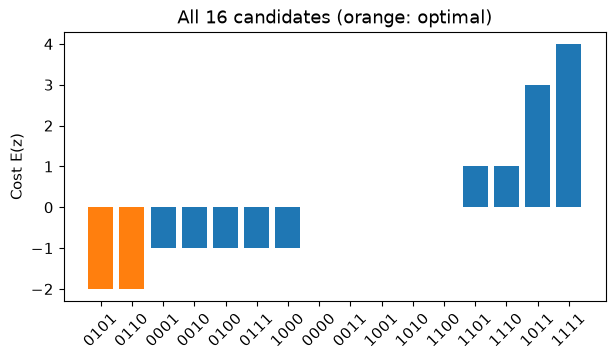

In [2]:
EDGES = [(0, 1), (0, 2), (0, 3), (2, 3)]


def cost(bits, edges=EDGES):
    """Return the MIS cost of an atom-order bitstring; lower is better."""
    return -bits.count("1") + 2 * sum(bits[i] == bits[j] == "1" for i, j in edges)


candidates = ["".join(b) for b in itertools.product("01", repeat=4)]
best = min(map(cost, candidates))
optima = [b for b in candidates if cost(b) == best]
print("Optimal sets:", optima, "→ nodes", [[i for i, x in enumerate(b) if x == "1"] for b in optima])

order = sorted(candidates, key=cost)
plt.bar(order, [cost(b) for b in order], color=["tab:orange" if b in optima else "tab:blue" for b in order])
plt.xticks(rotation=45)
plt.ylabel("Cost E(z)")
plt.title("All 16 candidates (orange: optimal)")
plt.show()

Two solutions tie: nodes {1, 2} (`0110`) and {1, 3} (`0101`). For 4 nodes brute force is instant; for 100 nodes there are $2^{100}$ candidates.

## 2. From graph to atoms

Atoms joined by an edge must blockade each other at the end of the pulse; the others must not. A pair blockades when its interaction $U_{ij} = C_6/r_{ij}^6$ exceeds the final detuning $\Delta_f$.

In notebook 1 the blockade radius compared $U$ with $\Omega$, the only energy in that pulse. Here the drive is off at the end of the pulse, and what an excitation gains is $\Delta_f$, so the radius is set by $C_6/R^6 = \Delta_f$.

Here $C_6$ enters the program itself, not only the emulation: we choose $\Omega$ and $\Delta_f$ relative to the **weakest edge interaction** $U$. $\Delta_f = 0.44\,U$ stays well below $U$, so every edge remains blockaded. $\Omega \approx U/5$ (at most 4 rad/µs) is small enough that the drive does not break the blockade. These are starting guesses; section 5 tests them. For a device with a different $C_6$, keep the same pulse and scale the spacing by $(C_6'/C_6)^{1/6}$, or keep the spacing and rescale the pulse.

weakest edge U = 6.0 rad/µs → Δf = 2.6, Ω = 1.1 rad/µs


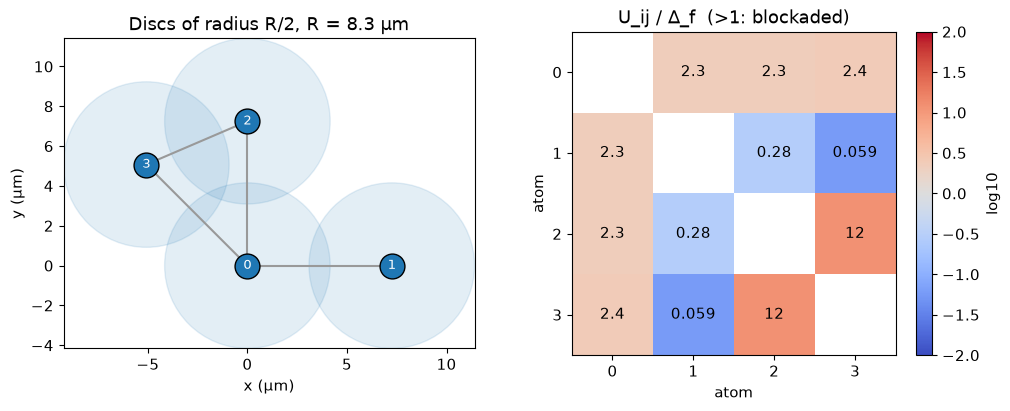

In [3]:
spacing = 7.25e-6  # metres
sites = [(x * spacing, y * spacing) for x, y in [(0, 0), (1, 0), (0, 1), (-0.7, 0.7)]]
weakest_edge = min(C6 / math.dist(sites[i], sites[j]) ** 6 for i, j in EDGES)
final_detuning = 0.44 * weakest_edge
omega_max = min(4e6, 0.1925 * weakest_edge)
print(f"weakest edge U = {weakest_edge / 1e6:.1f} rad/µs → Δf = {final_detuning / 1e6:.1f}, Ω = {omega_max / 1e6:.1f} rad/µs")

radius = draw.blockade_radius(C6, final_detuning)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
draw.register(sites, radius_um=radius, edges=EDGES, ax=left, title=f"Discs of radius R/2, R = {radius:.1f} µm")
r = np.array([[math.dist(a, b) for b in sites] for a in sites])
with np.errstate(divide="ignore"):
    ratio = np.where(r > 0, C6 / r**6 / final_detuning, np.nan)
image = right.imshow(np.log10(ratio), cmap="coolwarm", vmin=-2, vmax=2)
for i, j in itertools.product(range(4), repeat=2):
    if i != j:
        right.text(j, i, f"{ratio[i, j]:.2g}", ha="center", va="center")
right.set(title="U_ij / Δ_f  (>1: blockaded)", xticks=range(4), yticks=range(4), xlabel="atom", ylabel="atom")
fig.colorbar(image, ax=right, label="log10")
plt.show()

All four edges have $U_{ij} > \Delta_f$ and both non-edges have $U_{ij} < \Delta_f$: the geometry reproduces the graph. Every pair still interacts a little, which will matter in section 4.

<details><summary><b>Check yourself:</b> You double every distance. By how much do the interactions drop, and what keeps the same graph?</summary>

By $2^6 = 64$. Divide $\Delta_f$ (and $\Omega$) by 64 too, and every ratio $U_{ij}/\Delta_f$ stays the same. The pulse then needs to be longer, since everything is slower.

</details>

## 3. The annealing pulse

We use the **adiabatic** principle: start in a state that is easy to prepare, and change the Hamiltonian slowly enough that the system stays in its lowest-energy state.

- At the start, $\Delta < 0$ penalises excitations: the lowest-energy state is all atoms in `0`.
- At the end, $\Delta > 0$ rewards each excitation, while the blockade forbids excited neighbours: the lowest-energy state is the **maximum independent set**.
- The drive $\Omega$ ramps up and down to connect the two.

The pulse is piecewise linear with four samples. As notebook 1 showed, CUDA-Q evaluates each `ScalarOperator` at the schedule times and the target joins the samples linearly. So the function only has to return the sample at each schedule time; `np.interp` does that.

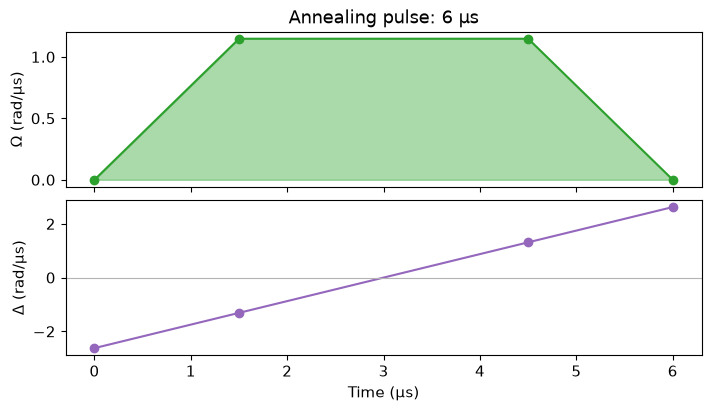

In [4]:
def rydberg_program(times, amplitude, detuning, atoms=sites):
    """Return the Rydberg Hamiltonian of a piecewise-linear pulse given by its samples."""
    return RydbergHamiltonian(
        atom_sites=atoms,
        amplitude=ScalarOperator(lambda t: float(np.interp(t.real, times, amplitude))),
        phase=ScalarOperator.const(0.0),
        delta_global=ScalarOperator(lambda t: float(np.interp(t.real, times, detuning))),
    )


def anneal(duration, detuning=final_detuning, omega=omega_max, atoms=sites):
    """Return the annealing Hamiltonian, its schedule and the waveform samples."""
    times = [0.0, duration / 4, 3 * duration / 4, duration]
    amplitude = [0.0, omega, omega, 0.0]
    detunings = [-detuning, -detuning / 2, detuning / 2, detuning]
    return rydberg_program(times, amplitude, detunings, atoms), Schedule(times, ["t"]), (times, amplitude, detunings)


hamiltonian, schedule, samples = anneal(6e-6)
draw.pulse(*samples, title="Annealing pulse: 6 µs")
plt.show()

<details><summary><b>Check yourself:</b> Why must the detuning start negative?</summary>

The atoms start in `0`. With $\Delta < 0$, all-`0` is the lowest-energy state, so the anneal starts in the lowest-energy state and can follow it to the MIS. Starting at $\Delta > 0$, the atoms would begin far from it.

</details>

## 4. Run and read the answer

In [5]:
# Predict: which fraction of the 1000 shots will be an optimal set? A number from 0 to 1, or None.
predicted_p_opt = None

P(optimal) = 0.871 ± 0.011;  mean cost = -1.86  (best possible -2)
you predicted None


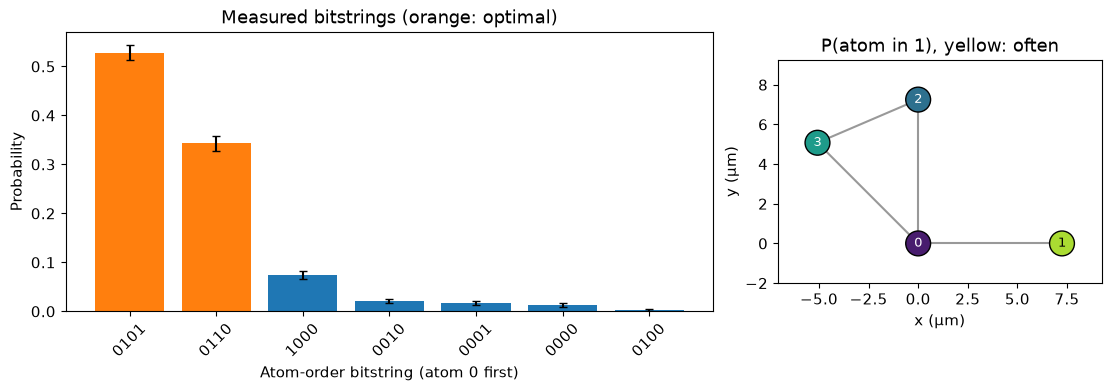

In [6]:
counts = dict(cudaq.evolve(hamiltonian, schedule=schedule, shots_count=1000).items())
p_opt, err = probability(counts, optima)
mean_cost = sum(n * cost(b) for b, n in counts.items()) / sum(counts.values())
print(f"P(optimal) = {p_opt:.3f} ± {err:.3f};  mean cost = {mean_cost:.2f}  (best possible {best})")
print(f"you predicted {predicted_p_opt}")

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained", width_ratios=[2, 1])
draw.counts(counts, highlight=optima, ax=left, title="Measured bitstrings (orange: optimal)")
draw.register(sites, edges=EDGES, values=rydberg_density(counts), ax=right, title="P(atom in 1), yellow: often")
plt.show()

Most shots return an optimal set. Bitstrings are in **atom order**: the first character is atom 0, so `0101` selects atoms 1 and 3. The right panel colours each atom by how often it was excited: atom 0, which touches every other node, almost never is.

The two optima are not sampled equally. They have the same graph cost, but not the same physical energy: in `0110`, atoms 1 and 2 are 10.3 µm apart, and in `0101`, atoms 1 and 3 are 13.3 µm apart, so `0110` pays a little more residual interaction and is sampled less often.

## 5. Tune the pulse on the GPU, then use the QPU

Two pulse parameters matter most: the **duration** (slower anneals follow the ground state better, but a real QPU has a limited coherence time) and the **final detuning** (too small and the reward for excitations is weak; too large and it overcomes the blockade of the weakest edge). Trying combinations on a QPU costs queue time and shots. On the GPU it costs seconds.

We launch the whole grid with `evolve_async` and then collect it:

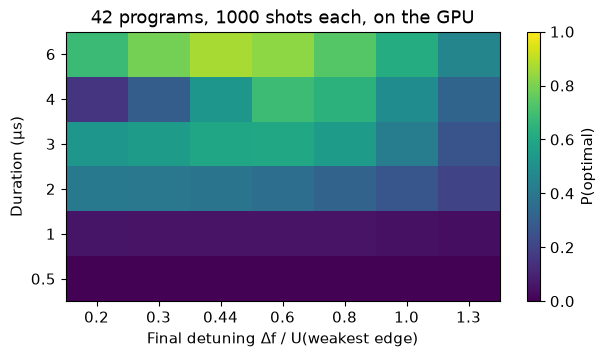

In [7]:
durations_us = [0.5, 1, 2, 3, 4, 6]
scales = [0.2, 0.3, 0.44, 0.6, 0.8, 1.0, 1.3]  # Δf in units of the weakest edge interaction
futures = {}
for d in durations_us:
    for s in scales:
        program, program_schedule, _ = anneal(d * 1e-6, s * weakest_edge)
        futures[d, s] = cudaq.evolve_async(program, schedule=program_schedule, shots_count=1000)
grid = np.array([[probability(dict(futures[d, s].get().items()), optima)[0] for s in scales] for d in durations_us])

plt.imshow(grid, origin="lower", cmap="viridis", vmin=0, vmax=1, aspect="auto")
plt.colorbar(label="P(optimal)")
plt.xticks(range(len(scales)), scales)
plt.yticks(range(len(durations_us)), durations_us)
plt.xlabel("Final detuning Δf / U(weakest edge)")
plt.ylabel("Duration (µs)")
plt.title(f"{len(futures)} programs, 1000 shots each, on the GPU")
plt.show()

Longer anneals generally succeed more often, though not monotonically: the dynamics are coherent, as in notebook 1. The detuning has a window: below it the atoms are not pushed to excite, above it ($\Delta_f > U$) the weakest edge no longer blockades and invalid sets appear. Now pick the best setting within a time budget, say 3 µs:

In [8]:
budget = [i for i, d in enumerate(durations_us) if d <= 3]
i, j = max(((i, j) for i in budget for j in range(len(scales))), key=lambda ij: grid[ij])
print(f"best within 3 µs: {durations_us[i]} µs, Δf = {scales[j]} U → P(optimal) = {grid[i, j]:.2f}")
hamiltonian, schedule, _ = anneal(durations_us[i] * 1e-6, scales[j] * weakest_edge)

best within 3 µs: 3 µs, Δf = 0.6 U → P(optimal) = 0.60


`hamiltonian` and `schedule` are now the program you would send to the QPU. In a scheduler job holding a Pasqal QPU, the only change is the target:

```python
cudaq.set_target("pasqal", machine="qrmi")
qpu_counts = cudaq.evolve(hamiltonian, schedule=schedule, shots_count=1000)
```

Before that, repeat the scan with the device's $C_6$ (see section 2) and check its pulse limits. A physical QPU adds noise and finite detection fidelity, so expect a lower P(optimal) than the ideal emulation. [Step 04](../04-slurm/README.md) shows this GPU → QPU hand-over as Slurm jobs.

<details><summary><b>Check yourself:</b> Why not always pick the longest anneal?</summary>

A QPU's atoms lose coherence over a few microseconds, so on hardware a long pulse collects more noise; each shot also takes longer. The GPU's ideal emulation has no such cost, which is why we set a time budget.

</details>

## 6. Challenge: beat the grid

The grid only tried one pulse shape. Within the same **3 µs**, can you beat it? Change the samples below: their values, their number, the timing, even the atom positions. The rules, loosely those of a real device:

- total duration at most 3 µs,
- $0 \le \Omega \le 4$ rad/µs and $|\Delta| \le 10$ rad/µs,
- atoms at least 5 µm apart,
- the final detuning must still blockade exactly the graph's edges.

`score` checks the rules, runs 1000 shots with a fixed seed and returns P(optimal). It starts from the grid's best program. Post your best score; the winning program is the one you would send to the QPU.

P(optimal) = 0.59   (the grid's best within 3 µs: 0.60)


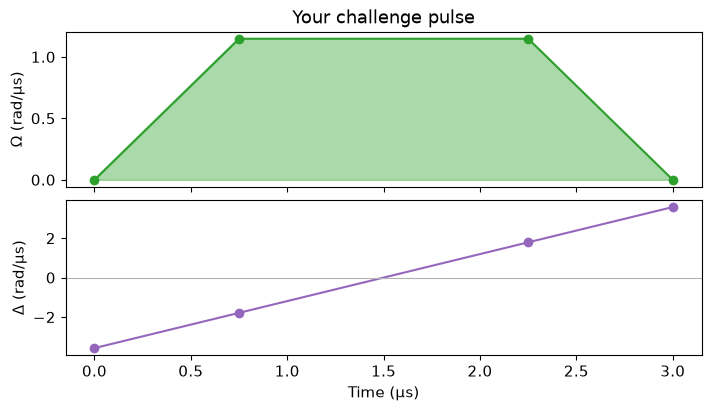

In [9]:
def score(times, amplitude, detuning, atoms=sites):
    """Check the challenge rules, run 1000 shots and return P(optimal), or None if a rule is broken."""
    pairs = list(itertools.combinations(range(len(atoms)), 2))
    rules = {
        "duration at most 3 µs": times[-1] - times[0] <= 3e-6 + 1e-12,
        "0 ≤ Ω ≤ 4 rad/µs": all(0 <= a <= 4e6 for a in amplitude),
        "|Δ| ≤ 10 rad/µs": all(abs(d) <= 10e6 for d in detuning),
        "atoms at least 5 µm apart": all(math.dist(atoms[i], atoms[j]) >= 5e-6 for i, j in pairs),
        "final detuning blockades exactly the edges": all(
            (C6 / math.dist(atoms[i], atoms[j]) ** 6 > detuning[-1]) == ((i, j) in EDGES) for i, j in pairs),
    }
    if not all(rules.values()):
        print("Rule broken:", ", ".join(rule for rule, ok in rules.items() if not ok))
        return None
    cudaq.set_random_seed(11)
    result = cudaq.evolve(rydberg_program(times, amplitude, detuning, atoms), schedule=Schedule(times, ["t"]), shots_count=1000)
    return probability(dict(result.items()), optima)[0]


challenge_times = [0.0, 0.75e-6, 2.25e-6, 3e-6]
challenge_amplitude = [0.0, omega_max, omega_max, 0.0]
challenge_detuning = [-0.6 * weakest_edge, -0.3 * weakest_edge, 0.3 * weakest_edge, 0.6 * weakest_edge]
challenge_sites = sites

challenge_p = score(challenge_times, challenge_amplitude, challenge_detuning, challenge_sites)
if challenge_p is not None:
    print(f"P(optimal) = {challenge_p:.2f}   (the grid's best within 3 µs: {grid[i, j]:.2f})")
draw.pulse(challenge_times, challenge_amplitude, challenge_detuning, title="Your challenge pulse")
plt.show()

<details><summary><b>Hint</b></summary>

The grid kept $\Omega$ at a fifth of the weakest edge, about 1.1 rad/µs. A stronger drive follows the lowest-energy state better in a short time: try $\Omega = 4$ rad/µs with a larger final detuning, around $0.8\,U$. That reaches about 0.8. Extra samples, for example a slower sweep where the detuning crosses zero, can do better still.

</details>

### Your turn: your own register

In a real application you place the atoms, and the graph follows from their distances: pairs closer than the blockade radius are edges. Below, six atoms on a hexagon. Change `my_sites` and run: the cell finds the edges, solves the graph by brute force and runs the anneal of section 3 on it.

6 edges; optimal sets: ['010101', '101010']
P(optimal) = 0.44


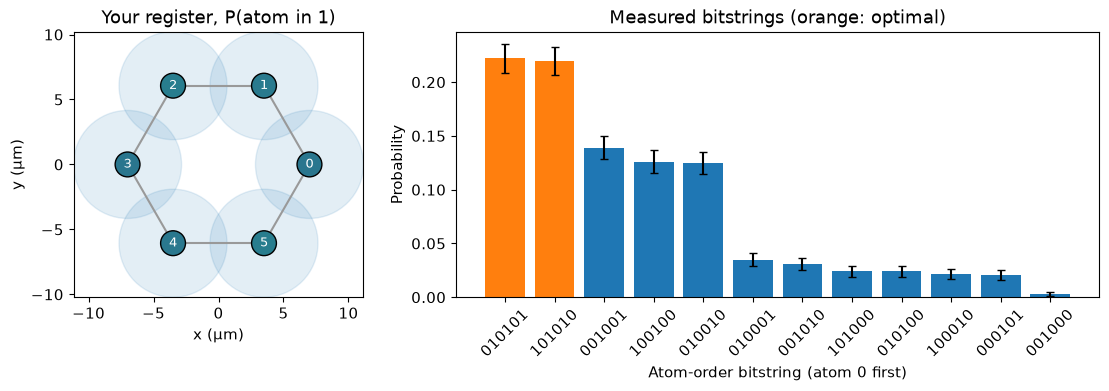

In [10]:
my_sites = [(7e-6 * math.cos(k * math.pi / 3), 7e-6 * math.sin(k * math.pi / 3)) for k in range(6)]  # metres

my_edges = [(i, j) for i, j in itertools.combinations(range(len(my_sites)), 2)
            if C6 / math.dist(my_sites[i], my_sites[j]) ** 6 > final_detuning]
my_candidates = ["".join(b) for b in itertools.product("01", repeat=len(my_sites))]
my_best = min(cost(b, my_edges) for b in my_candidates)
my_optima = [b for b in my_candidates if cost(b, my_edges) == my_best]
print(f"{len(my_edges)} edges; optimal sets: {my_optima}")

my_program, my_schedule, _ = anneal(6e-6, atoms=my_sites)
my_counts = dict(cudaq.evolve(my_program, schedule=my_schedule, shots_count=1000).items())
print(f"P(optimal) = {probability(my_counts, my_optima)[0]:.2f}")
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained", width_ratios=[1, 2])
draw.register(my_sites, radius_um=radius, edges=my_edges, values=rydberg_density(my_counts), ax=left, title="Your register, P(atom in 1)")
draw.counts(my_counts, highlight=my_optima, ax=right, title="Measured bitstrings (orange: optimal)")
plt.show()

<details><summary><b>Ideas</b></summary>

The hexagon has two optimal sets, every other atom: `101010` and `010101`. Try a square with 7 µm sides (the diagonals, 9.9 µm, are not edges), add an atom in the centre of the hexagon, or a line of five atoms. Keep atoms at least 5 µm apart. Beyond a dozen or so atoms, both the brute-force check and the exact emulation get slow; that is where QPUs and the solver libraries below come in.

</details>

### The easier way: Pasqal's solver libraries

We wrote every step by hand to see what CUDA-Q runs. For your own problems you do not have to: Pasqal's open-source libraries do the embedding, the pulse and the post-processing, and run on Pasqal's emulators and QPUs. They are built on Pulser rather than CUDA-Q. With [`maximum-independent-set`](https://github.com/pasqal-io/maximum-independent-set) (`pip install maximum-independent-set`), our graph takes three lines and returns both optima, {1, 2} and {1, 3}:

```python
import networkx as nx
from mis import BackendConfig, MISInstance, MISSolver, SolverConfig

solutions = MISSolver(MISInstance(nx.Graph(EDGES)), SolverConfig(backend=BackendConfig())).solve()
```

For problems written as a QUBO matrix, [`qubo-solver`](https://github.com/pasqal-io/qubo-solver) offers quantum, classical and hybrid solvers behind one interface.

## Key points

- A graph becomes a **register**: edges are pairs closer than the blockade radius. With another $C_6$, the register scales by the sixth root.
- An **annealing pulse** sweeps the detuning from negative to positive, ending in the MIS as the lowest-energy state.
- Piecewise-linear pulses map directly onto CUDA-Q schedules: one sample per schedule time.
- Each shot is a candidate solution; we score them with the classical cost and keep the best.
- The GPU is where you **tune** a program: a grid of 42 programs costs seconds, then the best one goes to the QPU.

<div class="alert alert-success">

**To go further**

- Change `spacing` to 8.0e-6. Which pairs are still blockaded? Rerun the grid: where is the window now?
- Replace the grid by an optimiser, e.g. `scipy.optimize.minimize_scalar` over the detuning, with the mean cost as objective. How many emulations does it need?
- Weighted graphs need a site-dependent detuning: see Pulser's [MWIS tutorial](https://docs.pasqal.com/pulser/tutorials/mwis/).

</div>